# sba-risk – ukázka použití

Balíček odhadne, s jakou pravděpodobností úvěr s ručením SBA (Small Business Administration)
skončí odepsáním, přidá 80% interval a doporučí, jestli se bance vyplatí úvěr schválit.

**Pro koho:** analytik banky, který posuzuje žádost malé firmy o úvěr s ručením SBA.

## Instalace

Potřebuješ Python 3.12 nebo novější. V terminálu:

```bash
pip install "sba-risk @ git+https://github.com/oli27l/sba-risk@v0.1.0"
```

Natrénovaný model je součástí balíčku, data z Kaggle nepotřebuješ.

In [1]:
import sba_risk
from sba_risk import FIELDS, predict_many, predict_risk

sba_risk.__version__

'0.1.0'

## Jeden úvěr

Úvěr zadáš jako slovník. Všechny údaje banka zná už při schválení.

In [2]:
loan = {
    "amount": 100_000,       # schválená částka v USD
    "sba_share": 0.75,       # SBA ručí za 75 % úvěru
    "naics": 44,             # odvětví: maloobchod (stačí první 2 číslice kódu NAICS)
    "state": "CA",           # firma je v Kalifornii
    "bank_state": "CA",      # banka taky
    "employees": 5,
    "new_jobs": 0,
    "retained_jobs": 5,
    "new_business": False,   # firma existuje déle než 2 roky
    "revolving": "N",        # nejde o revolvingový úvěr
}
predict_risk(loan)

{'probability': 0.20177363263047177,
 'risk': 0.30017595447592715,
 'low': 0.18258660782239872,
 'high': 0.4719346705248827,
 'break_even': 0.39204223548967615,
 'decision': 'schválit',
 'warnings': []}

| Výstup | Význam |
|---|---|
| `probability` | pravděpodobnost odepsání podle modelu |
| `risk` | pravděpodobnost posunutá nahoru – model se učil v letech s nízkým odepisováním a riziko podhodnocuje |
| `low`, `high` | 80% interval pro `risk`; na testovacích letech 2004–06 pokryl 83 % skupin úvěrů |
| `break_even` | riziko, nad kterým se bance úvěr v průměru nevyplatí (při marži 10 %) |
| `decision` | `schválit`, když `risk < break_even` |
| `warnings` | upozornění na neobvyklý vstup |

Všechny údaje, které funkce přijímá:

In [3]:
import pandas as pd

pd.Series(FIELDS, name="popis").to_frame()

,popis
amount,"schválená částka v USD (povinné, > 0)"
sba_share,"podíl záruky SBA 0–1, např. 0.75 (povinné)"
naics,"kód odvětví NAICS, stačí první 2 číslice, např..."
state,"stát firmy, dvě písmena, např. 'CA' (povinné)"
bank_state,"stát banky, dvě písmena (povinné)"
employees,počet zaměstnanců (povinné)
new_jobs,počet nových pracovních míst podle žádosti (po...
retained_jobs,počet udržených pracovních míst podle žádosti ...
new_business,True = nová firma (do 2 let)
franchise,True = franšíza (výchozí False)


## Více úvěrů najednou

`predict_many` vrátí tabulku, jeden řádek = jeden úvěr.

In [4]:
loans = {
    "maloobchod, CA": loan,
    "výroba, TX, záruka 50 %": {**loan, "naics": 31, "state": "TX", "bank_state": "TX", "sba_share": 0.5},
    "restaurace, nová firma": {**loan, "naics": 722511, "amount": 15_000, "new_business": True, "revolving": "Y"},
    "zdravotnictví, banka z jiného státu": {**loan, "naics": 62, "bank_state": "NY"},
}
table = predict_many(list(loans.values()))
table.index = list(loans)
table.drop(columns="warnings").round(3)

,probability,risk,low,high,break_even,decision
"maloobchod, CA",0.202,0.300,0.183,0.472,0.392,schválit
"výroba, TX, záruka 50 %",0.130,0.202,0.117,0.346,0.244,schválit
"restaurace, nová firma",0.089,0.142,0.079,0.256,0.392,schválit
"zdravotnictví, banka z jiného státu",0.263,0.377,0.240,0.558,0.392,schválit


## Marže banky

Úrokovou marži v datech nemáme, proto ji můžeš zadat (`margin` = celkový výnos ze splaceného
úvěru jako podíl z částky). Čím vyšší marže, tím víc rizika se bance vyplatí.

In [5]:
pd.DataFrame(
    {m: predict_risk(loans["výroba, TX, záruka 50 %"], margin=m) for m in (0.05, 0.10, 0.20)}
).T[["risk", "break_even", "decision"]]

,risk,break_even,decision
0.05,0.202169,0.138831,zamítnout
0.10,0.202169,0.243814,schválit
0.20,0.202169,0.392042,schválit


## Neobvyklý vstup → varování

Když je údaj mimo rozsah trénovacích dat, chybí nepovinný údaj nebo je rok mimo data,
funkce výsledek vrátí, ale varuje (`RiskWarning`). Varování jsou i ve výsledku.

In [6]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    result = predict_risk({**loan, "amount": 5_000_000, "revolving": None, "year": 2024})

for w in caught:
    print(f"{w.category.__name__}: {w.message}")
print()
print(f"riziko {result['risk']:.1%}, rozhodnutí: {result['decision']}")


riziko 15.7%, rozhodnutí: schválit


## Nesmyslný vstup → chyba

Nesmysl funkce odmítne, nikdy nevrátí tiché číslo.

In [7]:
bad_inputs = {
    "záruka v procentech": {**loan, "sba_share": 75},
    "záporná částka": {**loan, "amount": -100},
    "neexistující stát": {**loan, "state": "XX"},
    "chybí povinný údaj": {**loan, "retained_jobs": None},
    "překlep v názvu": {**loan, "ammount": 100_000},
}
for name, bad in bad_inputs.items():
    try:
        predict_risk(bad)
    except ValueError as error:
        print(f"{name}: {error}")

záruka v procentech: „sba_share“ musí být mezi 0 a 1, zadáno 75.0. Zadej podíl, ne procenta (75 % = 0.75).
záporná částka: „amount“ nesmí být menší než 0, zadáno -100.
neexistující stát: „state“ musí být zkratka státu USA ze dvou písmen, např. 'CA', ne 'XX'.
chybí povinný údaj: Chybí povinný údaj „retained_jobs“: počet udržených pracovních míst podle žádosti (povinné).
překlep v názvu: Neznámé údaje ['ammount']. Povolené: ['amount', 'bank_state', 'employees', 'franchise', 'low_doc', 'naics', 'new_business', 'new_jobs', 'retained_jobs', 'revolving', 'sba_share', 'state', 'year'].


## Jak riziko závisí na záruce SBA

Čím víc SBA ručí, tím víc rizika si banka může dovolit (práh `break_even` roste).

Pozor: že model u vysoké záruky předpovídá nižší riziko, **neznamená, že záruka riziko
snižuje**. Výše záruky se řídí typem programu SBA, ne rozhodnutím banky – graf ukazuje jen,
co model předpovídá pro takové úvěry. Schodovitý tvar je typický pro rozhodovací stromy.

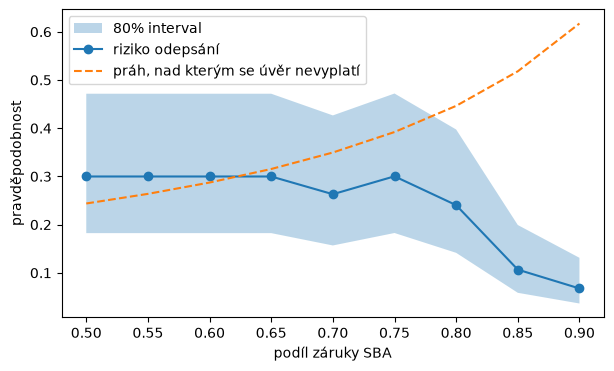

In [8]:
import matplotlib.pyplot as plt
import numpy as np

shares = np.linspace(0.5, 0.9, 9)
rows = pd.DataFrame([predict_risk({**loan, "sba_share": float(s)}) for s in shares], index=shares)

fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(shares, rows["low"], rows["high"], alpha=0.3, label="80% interval")
ax.plot(shares, rows["risk"], marker="o", label="riziko odepsání")
ax.plot(shares, rows["break_even"], linestyle="--", label="práh, nad kterým se úvěr nevyplatí")
ax.set_xlabel("podíl záruky SBA")
ax.set_ylabel("pravděpodobnost")
ax.legend()
plt.show()

## Omezení

- Model se učil na úvěrech schválených v letech **1990–2003** a byl ověřen na **2004–06**.
  Na dnešní úvěry ho nejde přenést bez nového učení.
- Nezná kreditní skóre dlužníka, které dnes banky používají.
- Pořadí úvěrů podle rizika je rozumné (AUC 0,68), ale nejistota je velká (interval je široký).
- Rozhodnutí je jen **zpřísnění**: data obsahují jen schválené úvěry, o zamítnutých
  žadatelích nic nevíme.

Víc v [README](https://github.com/oli27l/sba-risk).